In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
x,y=load_wine(return_X_y=True)

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [4]:
from xgboost import XGBClassifier

boosting=XGBClassifier(n_estimators=100, max_depth=3)
boosting.fit(x_train,y_train)

y_pred=boosting.predict(x_test)

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9444444444444444

# Feature Importance

In [5]:
importance=boosting.feature_importances_
names=load_wine().feature_names

imp=pd.Series(importance, index=names)
imp.sort_values(ascending=False)

od280/od315_of_diluted_wines    0.527081
color_intensity                 0.132167
proline                         0.130767
flavanoids                      0.079577
magnesium                       0.038331
proanthocyanins                 0.027889
malic_acid                      0.024980
nonflavanoid_phenols            0.010746
alcohol                         0.010664
hue                             0.010476
total_phenols                   0.003539
alcalinity_of_ash               0.003148
ash                             0.000635
dtype: float32

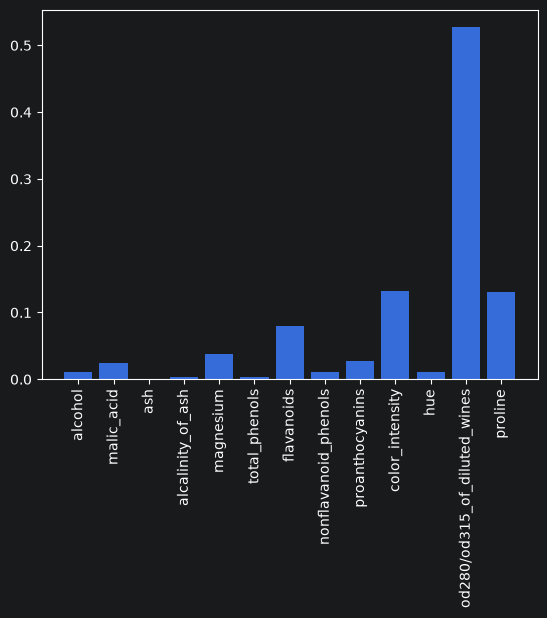

In [6]:
plt.bar(imp.index, imp)
plt.xticks(rotation=90)
plt.show()

# HyperParameter Tuning

## Grid Search

In [7]:
from sklearn.model_selection import GridSearchCV

xgb=XGBClassifier(random_state=42)

param={
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid=GridSearchCV(xgb,param,cv=5)
grid.fit(x,y)

print(grid.best_params_)
print(grid.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
0.9553968253968254


# PCA

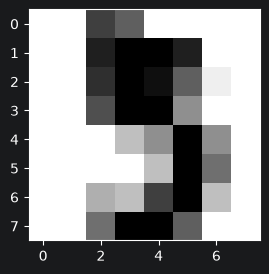

In [9]:
from sklearn.datasets import load_digits

digits=load_digits()

plt.figure(figsize=(3,3))
plt.imshow(digits.images[5], cmap='gray_r')
plt.show()

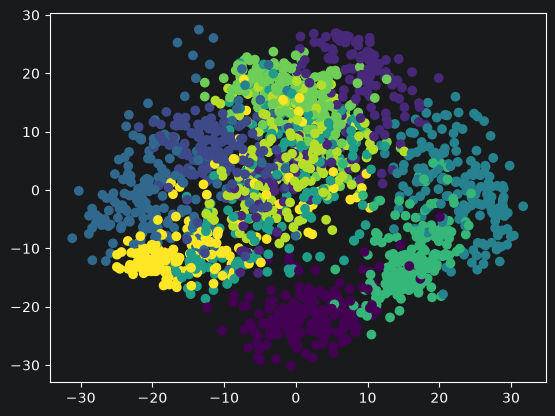

In [12]:
from sklearn.decomposition import PCA

x,y=load_digits(return_X_y=True)
pca=PCA(n_components=2)

reduced=pca.fit_transform(x)

plt.scatter(reduced[:,0], reduced[:,1],c=y)
plt.show()